# Guardian API · 미국 주식시장 관련성 파일럿
목표 기간 **2017-01-01~2026-10-25**. 세 시기의 일주일 구간에서 6개 전략을 비교한다.
이 노트북은 Guardian 공식 API만 사용한다. 이전 HTML 표본이나 외부 자료를 합치지 않는다.
기본 동작은 저장된 결과 조회이다. **API 키가 없으면 검색 건수·정밀도·규모를 추정하지 않는다.**

In [1]:
from pathlib import Path
import runpy
BASE=Path.cwd().resolve()
if not (BASE/"guardian_api_pilot.py").exists():
    BASE=BASE/"midterm paper"
api=runpy.run_path(str(BASE/"guardian_api_pilot.py"))
from guardian_api_config import load_key,STRATEGIES,STRATEGY_NOTES,PILOT_WINDOWS
import pandas as pd
import json
from IPython.display import display,Markdown
RESULTS=BASE/"results"/"guardian_api_pilot"
key,key_source=load_key(BASE)
print("API key configured:",bool(key),"| source:",key_source)
del key
print("Configure:",BASE/".env","→ GUARDIAN_API_KEY= 뒤에 키 입력")

API key configured: True | source: project_dotenv
Configure: C:\Users\rhffl\data_mining\midterm paper\.env → GUARDIAN_API_KEY= 뒤에 키 입력


## 1. 키 설정
같은 폴더의 `.env` 파일에서 **`GUARDIAN_API_KEY=` 뒤에 발급받은 키**를 넣고 저장한다.
환경변수도 지원하며 환경변수가 우선이다. 파일은 git에서 제외한다. 키를 셀이나 출력에 넣지 않는다.
[개발자 키 발급](https://open-platform.theguardian.com/access/).

일주일 범위는 아래와 같다. UTC 검색의 경계 버퍼를 추가한 뒤 실제 뉴욕 날짜로 자른다.
API total과 ET 구간 다운로드 수는 다를 수 있다.

In [2]:
display(pd.DataFrame([{"year":year,"start_et":start,"end_et":end} for year,(start,end) in PILOT_WINDOWS.items()]))
display(pd.DataFrame([{"query_strategy":name,"parameters":json.dumps(params),"rationale":STRATEGY_NOTES[name]} for name,params in STRATEGIES.items()]))

,year,start_et,end_et
0,2017,2017-01-09,2017-01-15
1,2020,2020-03-16,2020-03-22
2,2026,2026-10-19,2026-10-25


,query_strategy,parameters,rationale
0,anchors_global,"{""q"": ""\""Wall Street\"" OR \""S&P 500\"" OR Nasda...",정확한 미국시장 명칭 중심. 섹션 제한 없이 기술/경제 기사 포함. Wall Str...
1,anchors_business,"{""q"": ""\""Wall Street\"" OR \""S&P 500\"" OR Nasda...",동일 검색어 + Business. 정밀도 개선과 Technology 등 관련 기사 ...
2,geography_and_equity,"{""q"": ""(US OR \""U.S.\"" OR American OR \""Wall S...",미국 지리어 AND 주식시장 용어. 일반 미국주식 표현을 포괄하되 본문에 우연히 함...
3,broad_business_control,"{""q"": ""stocks OR equities OR \""Wall Street\"" O...",stocks/equities를 포함한 넓은 Business 대조군. 비미국 주식시장...
4,anchors_stock_market_tag,"{""q"": ""\""Wall Street\"" OR \""S&P 500\"" OR Nasda...",같은 명칭 검색 + stock-markets 태그. 실제 태그 ID 확인 후만 요청...
5,anchors_us_office,"{""q"": ""\""Wall Street\"" OR \""S&P 500\"" OR Nasda...",같은 검색 + 미국 제작 오피스. US 에디션/미국시장 관련성과 동일하지 않음.


## 2. 필요할 때만 파일럿 실행
키 설정 후 아래 `RUN_PILOT=True`로 바꾸거나 터미널에서 `python guardian_api_pilot.py`를 실행한다.
성공한 페이지는 재사용한다. 기본은 200건/페이지, 주간·전략당 최대 3페이지이다.
전체 기간은 전략당 1건짜리 **건수 메타데이터 요청**만 허용하고 전체 페이지를 순회하지 않는다.

In [3]:
RUN_PILOT=False
if RUN_PILOT:
    result=api["run"]()
else:
    print("Saved-results review only; no network requests.")

Saved-results review only; no network requests.


## 3. 상태와 검색 결과
미시도는 0건 검색과 다르다. `partial_page_cap`은 주간 전체 결과를 받지 못한 상태이다.

In [4]:
status=json.loads((RESULTS/"run_status.json").read_text(encoding="utf-8"))
print(json.dumps(status,ensure_ascii=False,indent=2))
comparison=pd.read_csv(RESULTS/"strategy_comparison.csv")
display(comparison)

{
  "status": "completed",
  "key_source": "project_dotenv",
  "api_requests_this_run": 28,
  "manual_sample_records": 124,
  "full_collection": false,
  "raw_retrieved_records": 374,
  "duplicate_count": 218,
  "unique_article_count": 156,
  "raw_records_scope": "ET pilot windows, including repeated strategy memberships",
  "api_results_received_including_utc_buffer": 425
}


,query_strategy,year,status,api_from_date,api_to_date,total_search_results,downloaded_records_with_utc_buffer,records_in_et_window,duplicates_within_strategy,unique_articles,pages_downloaded,pages_reported,page_size_observed,complete_api_window,total_changed_across_pages,error
0,anchors_global,2017,complete,2017-01-09,2017-01-16,36,36,34,0,34,1,1,200,True,False,NaN
1,anchors_global,2020,complete,2020-03-16,2020-03-23,53,53,45,0,45,1,1,200,True,False,NaN
2,anchors_global,2026,complete,2026-10-19,2026-10-26,33,33,30,0,30,1,1,200,True,False,NaN
3,anchors_business,2017,complete,2017-01-09,2017-01-16,9,9,7,0,7,1,1,200,True,False,NaN
4,anchors_business,2020,complete,2020-03-16,2020-03-23,15,15,12,0,12,1,1,200,True,False,NaN
5,anchors_business,2026,complete,2026-10-19,2026-10-26,6,6,5,0,5,1,1,200,True,False,NaN
6,geography_and_equity,2017,complete,2017-01-09,2017-01-16,36,36,35,0,35,1,1,200,True,False,NaN
7,geography_and_equity,2020,complete,2020-03-16,2020-03-23,90,90,78,0,78,1,1,200,True,False,NaN
8,geography_and_equity,2026,complete,2026-10-19,2026-10-26,42,42,38,0,38,1,1,200,True,False,NaN
9,broad_business_control,2017,complete,2017-01-09,2017-01-16,9,9,8,0,8,1,1,200,True,False,NaN


## 4. 중복과 메타데이터
전략별 소속은 보존하고 Guardian ID로 고유 기사를 센다. 에디션/제작 오피스는 시장 관련성 라벨이 아니다.

In [5]:
print((RESULTS/"deduplication_summary.json").read_text(encoding="utf-8"))
display(pd.read_csv(RESULTS/"section_office_counts.csv"))
display(pd.read_csv(RESULTS/"tag_counts.csv").head(30))
catalog=RESULTS/"catalog_inspection.json"
if catalog.exists():
    print("Sections/editions/tag catalog:",catalog)
else:
    print("Catalog not queried; no API metadata available.")

{
  "raw_retrieved_records": 374,
  "duplicate_count": 218,
  "unique_article_count": 156,
  "raw_records_scope": "ET pilot windows, including repeated strategy memberships",
  "api_results_received_including_utc_buffer": 425
}


,query_strategy,year,section,production_office,n_articles
0,anchors_business,2017,Business,UK,7
1,anchors_business,2020,Business,UK,10
2,anchors_business,2020,Business,US,2
3,anchors_business,2026,Business,AUS,2
4,anchors_business,2026,Business,UK,3
...,...,...,...,...,...
116,geography_and_equity,2026,Technology,UK,2
117,geography_and_equity,2026,Technology,US,2
118,geography_and_equity,2026,US news,US,6
119,geography_and_equity,2026,World news,AUS,4


,query_strategy,year,tag_id,tag_title,tag_type,n_articles
0,anchors_business,2017,business/business,Business,keyword,7
1,anchors_business,2017,business/currencies,Currencies,keyword,4
2,anchors_business,2017,business/davos-2017,Davos 2017,keyword,2
3,anchors_business,2017,business/debenhams,Debenhams,keyword,1
4,anchors_business,2017,business/dollar,Dollar,keyword,1
5,anchors_business,2017,business/dowjones,Dow Jones,keyword,1
6,anchors_business,2017,business/economics,Economics,keyword,3
7,anchors_business,2017,business/ftse,FTSE,keyword,4
8,anchors_business,2017,business/marksspencer,Marks & Spencer,keyword,1
9,anchors_business,2017,business/retail,Retail industry,keyword,1


Sections/editions/tag catalog: C:\Users\rhffl\data_mining\midterm paper\results\guardian_api_pilot\catalog_inspection.json


## 5. 연도별 무작위 수동 검토 표본
`manual_review_sample.csv`에서 `relevant_us_equity_market`에 1/0을 입력한다.
연도별 고유 기사 합집합에서 최대 50건을 고정 시드로 추출한다. 충분하지 않으면 있는 기사만 쓴다.
전략별 소속은 `query_strategy`에 함께 표시한다. 입력한 라벨은 재실행 시 보존된다.
키가 없는 초기 상태의 파일은 **헤더만 있는 템플릿**이다.

In [6]:
review=pd.read_csv(RESULTS/"manual_review_sample.csv",keep_default_na=False)
print("Actual sampled articles:",len(review))
display(review)
display(pd.read_csv(RESULTS/"manual_precision.csv"))

Actual sampled articles: 124


,year,guardian_id,published_at,published_at_utc,published_at_et,date_et,title,description,section,tags,url,query_strategy,relevant_us_equity_market,review_notes
0,2017,business/live/2017/jan/11/wef-global-economic-...,2017-01-11T18:07:10Z,2017-01-11T18:07:10+00:00,2017-01-11T13:07:10-05:00,2017-01-11,Carney tells MPs Brexit no longer biggest risk...,Rising income inequality and the polarisation ...,Business,"[{""id"": ""business/series/guardian-business-liv...",https://www.theguardian.com/business/live/2017...,anchors_business | anchors_global | anchors_st...,0,Exclude: primarily political/social/foreign-lo...
1,2017,us-news/2017/jan/13/fbi-investigation-donald-t...,2017-01-13T19:37:25Z,2017-01-13T19:37:25+00:00,2017-01-13T14:37:25-05:00,2017-01-13,"Angering Congress, James Comey won't address T...",FBI director’s refusal to clarify potential in...,US news,"[{""id"": ""us-news/fbi"", ""type"": ""keyword"", ""sec...",https://www.theguardian.com/us-news/2017/jan/1...,anchors_global | anchors_us_office | geography...,0,Exclude: primarily political/social/foreign-lo...
2,2017,us-news/2017/jan/12/james-mattis-mike-pompeo-c...,2017-01-12T20:25:55Z,2017-01-12T20:25:55+00:00,2017-01-12T15:25:55-05:00,2017-01-12,"Russia is trying to smash Nato, James Mattis s...","Defense secretary nominee and Mike Pompeo, cho...",US news,"[{""id"": ""us-news/trump-administration"", ""type""...",https://www.theguardian.com/us-news/2017/jan/1...,anchors_global | anchors_us_office | geography...,0,Exclude: primarily political/social/foreign-lo...
3,2017,politics/blog/live/2017/jan/10/jeremy-corbyns-...,2017-01-10T18:03:46Z,2017-01-10T18:03:46+00:00,2017-01-10T13:03:46-05:00,2017-01-10,Corbyn unveils plans to curb high pay but back...,Rolling coverage of the day’s political develo...,Politics,"[{""id"": ""politics/series/politics-live-with-an...",https://www.theguardian.com/politics/blog/live...,anchors_global | geography_and_equity,0,Exclude: primarily political/social/foreign-lo...
4,2017,us-news/2017/jan/09/meryl-streep-donald-trump-...,2017-01-09T13:16:11Z,2017-01-09T13:16:11+00:00,2017-01-09T08:16:11-05:00,2017-01-09,Meryl Streep rips the 'bully' in Trump,Streep delivers an emotional speech while La L...,US news,"[{""id"": ""us-news/series/guardian-us-briefing"",...",https://www.theguardian.com/us-news/2017/jan/0...,anchors_global | anchors_us_office | geography...,0,Exclude: primarily political/social/foreign-lo...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,2026,technology/2026/oct/21/elon-musk-tesla-spacex,2026-10-21T23:03:16Z,2026-10-21T23:03:16+00:00,2026-10-21T19:03:16-04:00,2026-10-21,Tesla beats earnings projections after Musk fl...,Musk says ‘there’s a lot of merit’ to potentia...,Technology,"[{""id"": ""technology/tesla"", ""type"": ""keyword"",...",https://www.theguardian.com/technology/2026/oc...,anchors_global | anchors_us_office | geography...,1,Include: explicit market/macro/sector/company ...
120,2026,business/2026/oct/20/what-does-the-approval-of...,2026-10-20T18:58:20Z,2026-10-20T18:58:20+00:00,2026-10-20T14:58:20-04:00,2026-10-20,What does the UK’s approval of the Jackdaw gas...,Decision has implications for household energy...,Business,"[{""id"": ""business/oil"", ""type"": ""keyword"", ""se...",https://www.theguardian.com/business/2026/oct/...,broad_business_control | geography_and_equity,0,Exclude: primarily political/social/foreign-lo...
121,2026,us-news/2026/oct/23/billionaire-glenn-dubin-mo...,2026-10-23T18:42:41Z,2026-10-23T18:42:41+00:00,2026-10-23T14:42:41-04:00,2026-10-23,Why did an Epstein-linked billionaire step dow...,The board change is the latest development for...,US news,"[{""id"": ""us-news/jeffrey-epstein"", ""type"": ""ke...",https://www.theguardian.com/us-news/2026/oct/2...,anchors_global | anchors_us_office | geography...,0,Exclude: primarily political/social/foreign-lo...
122,2026,australia-news/2026/oct/20/morning-mail-tuesda...,2026-10-19T19:52:47Z,2026-10-19T19:52:47+00:00,2026-10-19T15

,query_strategy,year,n_sampled,n_reviewed,precision,wilson_95_low,wilson_95_high,scope
0,anchors_global,2017,34,34,0.058824,0.016283,0.190936,uniform sample of downloaded unique union; tru...
1,anchors_global,2020,28,28,0.285714,0.152540,0.470593,uniform sample of downloaded unique union; tru...
2,anchors_global,2026,30,30,0.266667,0.141827,0.444480,uniform sample of downloaded unique union; tru...
3,anchors_business,2017,7,7,0.142857,0.025680,0.513128,uniform sample of downloaded unique union; tru...
4,anchors_business,2020,8,8,0.750000,0.409275,0.928521,uniform sample of downloaded unique union; tru...
5,anchors_business,2026,5,5,0.800000,0.375535,0.963776,uniform sample of downloaded unique union; tru...
6,geography_and_equity,2017,35,35,0.057143,0.015813,0.186071,uniform sample of downloaded unique union; tru...
7,geography_and_equity,2020,47,47,0.234043,0.136033,0.372243,uniform sample of downloaded unique union; tru...
8,geography_and_equity,2026,38,38,0.263158,0.149716,0.420088,uniform sample of downloaded unique union; tru...
9,broad_business_control,2017,8,8,0.125000,0.022417,0.470888,uniform sample of downloaded unique union; tru...


## 6. 전체 기간 수집량·비용 추정
API 메타데이터와 관측 JSON 크기로 계산한다. 버퍼 구간·일일 한도·통신 지연 한계를 함께 읽는다. 조회하지 못한 숫자는 비워 둔다.

In [7]:
display(pd.read_csv(RESULTS/"volume_estimates.csv"))
display(Markdown((BASE/"GUARDIAN_API_PILOT_REVIEW.md").read_text(encoding="utf-8")))

,query_strategy,status,api_total_with_utc_buffer,estimated_api_calls,page_size_observed,runtime_rate_floor_seconds,minimum_quota_days,approx_raw_bytes,mean_observed_raw_bytes_per_article,basis
0,anchors_global,metadata_based_upper_window_estimate,12103,61,200,66.0,1,1.064075e+08,8791.827869,full-period one-result metadata query; UTC buf...
1,anchors_business,metadata_based_upper_window_estimate,3644,19,200,19.8,1,3.401261e+07,9333.866667,full-period one-result metadata query; UTC buf...
2,geography_and_equity,metadata_based_upper_window_estimate,16600,83,200,90.2,1,1.496304e+08,9013.880952,full-period one-result metadata query; UTC buf...
3,broad_business_control,metadata_based_upper_window_estimate,5055,26,200,27.5,1,4.494012e+07,8890.230769,full-period one-result metadata query; UTC buf...
4,anchors_stock_market_tag,metadata_based_upper_window_estimate,2514,13,200,13.2,1,2.357780e+07,9378.600000,full-period one-result metadata query; UTC buf...
5,anchors_us_office,metadata_based_upper_window_estimate,4657,24,200,25.3,1,3.349133e+07,7191.609756,full-period one-result metadata query; UTC buf...


# Guardian API 2차 파일럿 비교

목표 기간: **2017-01-01~2026-10-25**. 상태: **completed**.
키 설정 위치 확인 결과: `project_dotenv`. 키 값은 기록하지 않는다.

## 실제 실행 상태

UTC 버퍼 포함 API 수신 레코드 425건.
ET 파일럿 구간 내 전략 소속 중복 포함 관측치 374건,
중복 218건, 고유 기사 156건.
키가 없으면 이 0은 실제 검색 결과 0건을 뜻하지 않는다. API total·규모 추정은 미조회로 남긴다.
이전 공개 HTML 9건은 공식 API 비교 자료에 넣지 않았다.

| 전략 | 2017 | 2020 | 2026 |
|---|---|---|---|
| anchors_global | complete; API total=36; ET unique=34 | complete; API total=53; ET unique=45 | complete; API total=33; ET unique=30 |
| anchors_business | complete; API total=9; ET unique=7 | complete; API total=15; ET unique=12 | complete; API total=6; ET unique=5 |
| geography_and_equity | complete; API total=36; ET unique=35 | complete; API total=90; ET unique=78 | complete; API total=42; ET unique=38 |
| broad_business_control | complete; API total=9; ET unique=8 | complete; API total=22; ET unique=18 | complete; API total=8; ET unique=7 |
| anchors_stock_market_tag | complete; API total=6; ET unique=6 | complete; API total=12; ET unique=11 | complete; API total=7; ET unique=5 |
| anchors_us_office | complete; API total=9; ET unique=9 | complete; API total=20; ET unique=16 | complete; API total=12; ET unique=10 |

## 검색 전략

- **anchors_global**: `{"q": "\"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\" OR \"US stocks\" OR \"US markets\""}`. 정확한 미국시장 명칭 중심. 섹션 제한 없이 기술/경제 기사 포함. Wall Street의 비시장 용례는 수동 검토.
- **anchors_business**: `{"q": "\"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\" OR \"US stocks\" OR \"US markets\"", "section": "business"}`. 동일 검색어 + Business. 정밀도 개선과 Technology 등 관련 기사 누락을 비교.
- **geography_and_equity**: `{"q": "(US OR \"U.S.\" OR American OR \"Wall Street\" OR \"Federal Reserve\") AND (stocks OR equities OR \"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\")"}`. 미국 지리어 AND 주식시장 용어. 일반 미국주식 표현을 포괄하되 본문에 우연히 함께 나오는 용례 점검.
- **broad_business_control**: `{"q": "stocks OR equities OR \"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\"", "section": "business"}`. stocks/equities를 포함한 넓은 Business 대조군. 비미국 주식시장 혼입을 점검.
- **anchors_stock_market_tag**: `{"q": "\"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\" OR \"US stocks\" OR \"US markets\"", "tag": "business/stock-markets"}`. 같은 명칭 검색 + stock-markets 태그. 실제 태그 ID 확인 후만 요청; 옛 기사 태깅 누락 가능.
- **anchors_us_office**: `{"q": "\"Wall Street\" OR \"S&P 500\" OR Nasdaq OR \"Dow Jones\" OR \"US stocks\" OR \"US markets\"", "production-office": "us"}`. 같은 검색 + 미국 제작 오피스. US 에디션/미국시장 관련성과 동일하지 않음.


## 키 설정과 실행

같은 폴더의 **`.env`**에서 다음 등호 뒤에 개발자 키를 입력한다.

```dotenv
GUARDIAN_API_KEY=발급받은_키
```

파일은 git에서 제외된다. `.env.example`은 배포용 빈 예시이다.
현재 프로세스의 `GUARDIAN_API_KEY` 환경변수가 있으면 `.env`보다 우선한다.
VS Code 커널/터미널을 이미 실행 중이라면 파일 방식이 간단하다. 키를 채팅이나 노트북에 쓰지 않는다.

```powershell
python guardian_api_pilot.py
```

실제 환경 실행 파일이 필요하면 `C:\Users\rhffl\anaconda3\envs\hwenv\python.exe`를 사용한다.
등록: [Guardian Developer API](https://open-platform.theguardian.com/access/).

## 표본·시각·중복 검증

- 2017-01-09~15, 2020-03-16~22, 2026-10-19~25의 일주일 구간을 비교한다.
- 모든 원응답은 조건 해시+연도+전략+페이지별 저장이다. 성공한 캐시는 재사용한다.
- 기본 page-size=200, 주간별 최대 3페이지다. 응답의 pageSize/pages를 확인하며 실제 지원 여부는 키 설정 후 검증한다.
  400이면 지원되지 않은 파라미터/페이지 크기를 보고하고 조용히 조건을 바꾸지 않는다.
- `partial_page_cap`이면 검색 결과 전체를 받지 못한 것이다. 다운로드 순서는 oldest이므로 이때는 주간 전체의 무작위 표본이 아니다.
- 날짜 필터는 UTC 날짜 끝에 하루 버퍼를 두고, 원래 발행 문자열·UTC·America/New_York·ET 날짜를 저장한다.
  API total은 버퍼 구간의 값이다. 실제 ET 구간 문서 수는 별도 저장하며 둘을 같은 수로 표시하지 않는다.
- 안정적인 Guardian ID(없으면 URL)로 중복을 제거하고 전략별 소속을 모두 보존한다.
- `manual_review_sample.csv`: 다운로드된 고유 기사 합집합에서 연도별 최대 50건을 고정 시드로 무작위 추출한다.
  `relevant_us_equity_market`는 빈칸이다. 사람이 1/0을 입력하면 다시 실행 시 전략별 precision과 Wilson 구간을 계산한다.
  표본의 전략별 수는 `manual_precision.csv`에서 확인한다. 일부 전략에 검토 표본이 적으면 정밀도 결론을 유보한다.
- 기존 사람이 입력한 라벨은 ID로 재사용하고 `manual_review_labels.csv`에도 보존한다.
- sections·editions 목록과 keyword tags·productionOffice 분포를 저장한다. 미국 제작 오피스/US 에디션은 시장 관련성 라벨이 아니다.
- q 검색 범위와 반환한 headline/trailText의 범위가 같다고 가정하지 않는다. 반환한 관측 텍스트 자체의 관련성을 수동 검토한다.
- 캐시 시점이 다르면 검색 인덱스 변경으로 페이지가 달라질 수 있다. total 변화는 완전 수집으로 표시하지 않는다.

## 전체 기간 규모 추정

각 전략당 **page-size=1, page=1의 메타데이터 요청만** 전체 목표 기간에 보낸다.
full-period pages를 순회하는 기능은 없다. 이 total과 파일럿의 실제 페이지 크기·원응답 바이트를 사용한다.
UTC 경계 버퍼가 있어 수집량은 약간 넓은 범위의 추정값이며 전략별 total을 더해 합집합 수로 쓰지 않는다.

- API 호출 수 ≈ ceil(total / observed pageSize).
- 속도상 최소 실행 시간 ≈ (호출 수 − 1) × 1.1초. 통신 지연/일일 한도 대기는 제외한다.
- 일일 한도상 최소 일수 ≈ ceil(호출 수 / 500). 같은 키의 다른 사용량은 알 수 없다.
- 원응답 저장 용량 ≈ total × 파일럿에서 관측된 JSON 바이트/문서. 수정·태그 길이에 따라 달라진다.
- `volume_estimates.csv`에 근거와 수치를 저장한다. 키가 없거나 메타데이터 실패 시 숫자를 만들지 않는다.
- 세 주간만 10년으로 단순 외삽하지 않는다. COVID 주간은 보통 시기의 무작위 표본이 아니다.

공식 개발자 한도: 초당 1회·일 500회. 로컬 클라이언트는 1.1초 간격, 실행당 최대 90요청,
보수적인 최근 24시간 500요청 제한을 사용한다. robots 요청도 로컬 예산에 포함한다.
401/403/418/429는 자동 재시도하지 않고 전체 실행을 중단한다.
이는 **Content API 응답**의 처리이다. `/robots.txt`의 401은 별도 보조 검사 실패로 기록하고
`/search` 인증 실패로 판정하지 않는다. 실제로 받은 robots 금지 규칙은 준수하며 공식 JSON API 외 HTML 경로는 허용하지 않는다.

이전 중단 경로는 `fetch → PublicClient.get → robots 요청 → PublicClient._request`가 401을
`AccessError`로 바꾼 후, 래퍼 `logged_request`가 엔드포인트를 구분하지 않고
`halted=True`와 `PilotStopped`를 발생시킨 것이었다.
수정 후 robots 검사는 분리했고, 실제 API 401/403/429 중단·요청 간격·예산은 유지했다.

## 현재 추천과 채택 조건

**잠정 기준 후보는 `anchors_global`**이다. 명확한 미국시장 명칭을 쓰면서 섹션·제작 오피스 제한으로
Technology 등 관련 기사나 영국에서 작성한 미국시장 뉴스를 미리 제외하지 않는 접근이다.
이는 실측 정밀도 우승 전략이라는 뜻이 아니다. 키가 없거나 수동 검토가 끝나지 않았다면 최종 선택을 하지 않는다.
`geography_and_equity`의 추가 포괄성과 Business/태그/오피스 제한의 정밀도·누락을 세 연도별로 비교한 후 결정한다.
FGI 상관이 높다는 이유로 검색 전략을 고르지 않는다.

Guardian만 다룬다. Reddit/FNSPID/FGI/S&P 500 결합, 일별 감성 집계, 전체 수집은 실행하지 않는다.
Reddit은 전 기간 주 자료로 보지 않고, FNSPID는 향후 독립적인 2017~2023 강건성 자료로만 검토한다.

근거: [공식 검색/필드 문서](https://open-platform.theguardian.com/documentation/),
[공식 클라이언트의 검색·태그·페이지 처리](https://github.com/guardian/content-api-scala-client),
[개발자 키·한도](https://open-platform.theguardian.com/access/).


## 7. 제공 라벨 반영 · 기사 수 × precision
최종 전략은 보류한다. 전체 API 기사 수에 파일럿 precision을 곱한 값은 **같은 precision이 전체 기간에 유지된다는 조건부 시나리오**이다.
작은 표본과 연도별 차이를 함께 확인한다. 참고 구간은 이항 작업모형의 Wilson 구간이며 시간 외삽 불확실성을 포함하지 않는다.
자료 재계산은 `python guardian_strategy_yield.py`로 한다. 이 과정은 네트워크 요청을 보내지 않는다.

,query_strategy,reviewed,precision,precision_wilson_95_low,precision_wilson_95_high,full_period_api_count_with_utc_buffer,scenario_relevant_count,scenario_noise_count,decision_status
0,anchors_stock_market_tag,18,0.6111,0.3862,0.7969,2514,1536.3333,977.6667,not_finalized
1,anchors_business,20,0.5500,0.3421,0.7418,3644,2004.2000,1639.8000,not_finalized
2,broad_business_control,26,0.5000,0.3206,0.6794,5055,2527.5000,2527.5000,not_finalized
3,anchors_global,92,0.1957,0.1275,0.2882,12103,2367.9783,9735.0217,not_finalized
4,geography_and_equity,120,0.1917,0.1313,0.2712,16600,3181.6667,13418.3333,not_finalized
5,anchors_us_office,29,0.1379,0.0550,0.3056,4657,642.3448,4014.6552,not_finalized


,query_strategy,year,unique_articles,n_reviewed,precision,pilot_review_is_census
0,anchors_global,2017,34,34,0.058824,True
1,anchors_global,2020,45,28,0.285714,False
2,anchors_global,2026,30,30,0.266667,True
3,anchors_business,2017,7,7,0.142857,True
4,anchors_business,2020,12,8,0.750000,False
5,anchors_business,2026,5,5,0.800000,True
6,geography_and_equity,2017,35,35,0.057143,True
7,geography_and_equity,2020,78,47,0.234043,False
8,geography_and_equity,2026,38,38,0.263158,True
9,broad_business_control,2017,8,8,0.125000,True


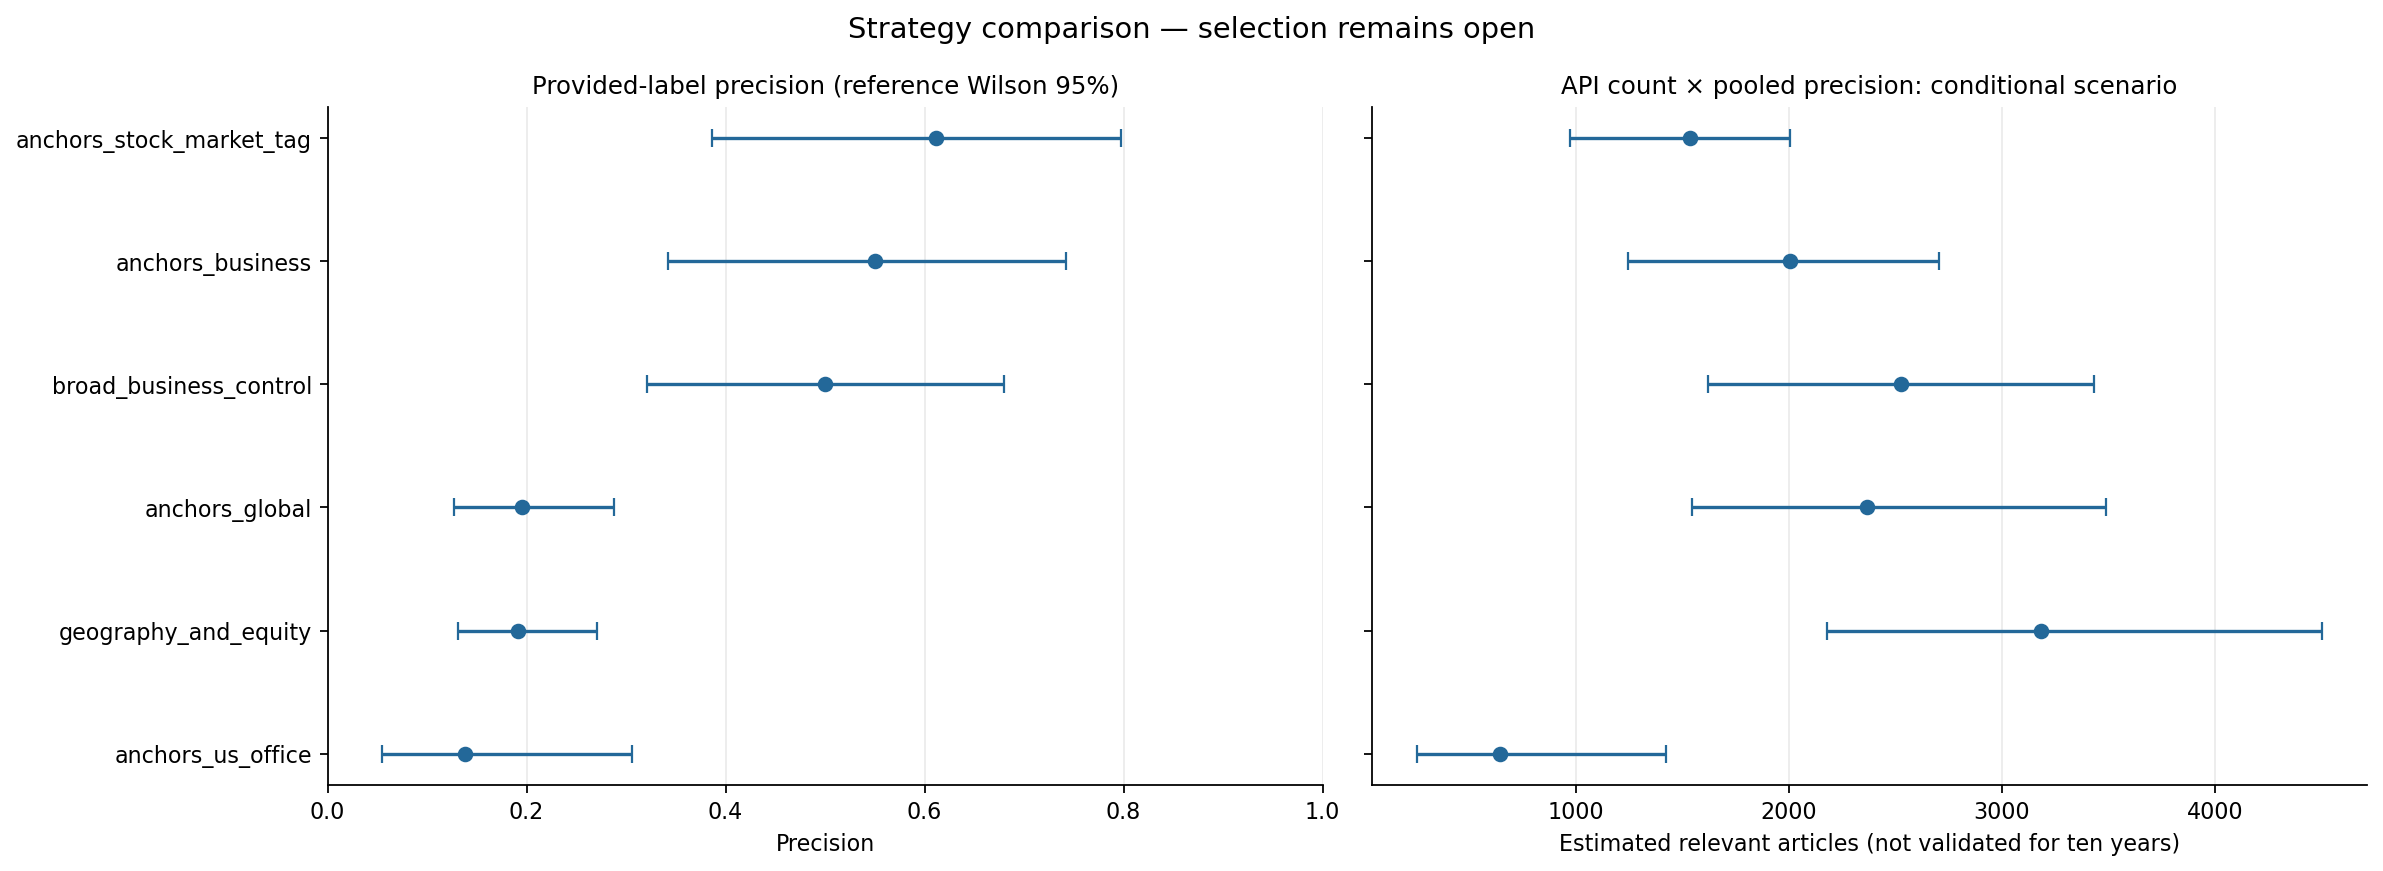

In [8]:
comparison_path=RESULTS/"strategy_yield_comparison.csv"
if comparison_path.exists():
    comparison=pd.read_csv(comparison_path)
    display(comparison[["query_strategy","reviewed","precision","precision_wilson_95_low","precision_wilson_95_high","full_period_api_count_with_utc_buffer","scenario_relevant_count","scenario_noise_count","decision_status"]].round(4))
    display(pd.read_csv(RESULTS/"strategy_yield_by_year.csv")[["query_strategy","year","unique_articles","n_reviewed","precision","pilot_review_is_census"]])
    from IPython.display import Image
    display(Image(filename=str(BASE/"figures/guardian_strategy_yield.png"),width=1100))
else:
    print("Provided-label yield comparison has not been generated.")